# 01 · Integrar, limpiar y explorar los datos

**Objetivo:** construir una base transaccional verificable sin perder compras ni utilizar el resultado de la investigación como predictor.

**Tiempo de práctica: 20 minutos.** Datos enteramente sintéticos: 5.000 clientes, 200.000 compras y 25% de fraude por diseño. Este cuaderno es una solución ejecutable; modifica una comprobación y explica tu decisión para producir evidencia individual.

## Preparación
Seleccione el kernel `.venv`. Ejecute las celdas en orden. Los diccionarios están en `data/data_dict/`. No use la referencia limpia de `build_workshop/qa/facilitador/` para resolver el ejercicio.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
assert (ROOT / 'data/transacciones.parquet').exists(), 'Abra el repositorio y seleccione .venv'
sys.path.insert(0, str(ROOT / 'python'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from taller import *
print('Repositorio:', ROOT.name)


Matplotlib is building the font cache; this may take a moment.


Repositorio: taller_codex_compensar_ufa


## 1. Leer cuatro formatos
El Excel describe clientes; el CSV con `;` contiene 25 variables de buró; Parquet contiene compras; el TXT con `|` contiene seguimiento y etiquetas. Una fila representa una compra en la tabla central.

In [2]:
clientes, buro, transacciones, observacion = load_inputs()
display(pd.DataFrame({'fuente':['clientes','buro','transacciones','observacion'],
                      'filas':[len(clientes),len(buro),len(transacciones),len(observacion)],
                      'columnas':[clientes.shape[1],buro.shape[1],transacciones.shape[1],observacion.shape[1]]}))
display(transacciones.head(3))

,fuente,filas,columnas
0,clientes,5000,13
1,buro,5000,27
2,transacciones,200000,23
3,observacion,200000,9


,id_transaccion,id_cliente,id_tarjeta,fecha_hora,fecha,hora,monto_cop,moneda_liquidacion,id_comercio,nombre_comercio,...,ciudad_compra,numero_cuotas,id_dispositivo,metodo_autenticacion,uso_3ds,resultado_autenticacion,latencia_red_ms,version_sdk,sistema_origen,indicador_reintento
0,TRX0077701,CLI03199,TAR03199,2026-01-01 00:05:46,2026-01-01,00:05:46,54014.54,COP,COM0505,Comercio_Sintetico_0505,...,Bogota,1,NaN,CHIP_PIN,0,EXITOSA,NaN,<NA>,CORE_TARJETAS,0
1,TRX0183941,CLI04573,TAR04573,2026-01-01 00:06:08,2026-01-01,00:06:08,221940.89,COP,COM0191,Comercio_Sintetico_0191,...,Medellin,1,DEV04572,3DS,1,EXITOSA,NaN,<NA>,CORE_TARJETAS,0
2,TRX0141171,CLI00371,TAR00371,2026-01-01 00:06:56,2026-01-01,00:06:56,244916.41,COP,COM0387,Comercio_Sintetico_0387,...,Cali,3,DEVNEW141170,3DS,1,EXITOSA,NaN,<NA>,CORE_TARJETAS,0


## 2. Validar las llaves antes de unir
Un cliente tiene muchas compras. Cada compra tiene una sola observación. `validate=` evita que una unión muchos-a-muchos multiplique silenciosamente las filas.

In [3]:
assert clientes.id_cliente.is_unique and buro.id_cliente.is_unique
assert transacciones.id_transaccion.is_unique and observacion.id_transaccion.is_unique
assert not transacciones[['id_cliente','id_transaccion','id_tarjeta']].isna().any().any()
assert set(transacciones.id_cliente) == set(clientes.id_cliente) == set(buro.id_cliente)
assert set(transacciones.id_transaccion) == set(observacion.id_transaccion)
unida = transacciones[['id_transaccion','id_cliente']].merge(
    clientes[['id_cliente','edad']], on='id_cliente', validate='many_to_one').merge(
    observacion[['id_transaccion','es_fraude']], on='id_transaccion', validate='one_to_one')
assert len(unida) == 200_000
print('Unión:', len(unida), 'filas. Fraudes:', int(unida.es_fraude.sum()))

Unión: 200000 filas. Fraudes: 50000


## 3. Perfilar calidad y variabilidad
Los nulos estructurales de dispositivo en POS tienen un significado distinto de la pérdida de telemetría. Una variable casi constante puede ser válida, aunque aporte poco al modelo.

,tipo,nulos_pct,distintos,moda_pct
version_sdk,string,95.00,3,33.42
latencia_red_ms,float64,85.00,14763,0.03
id_dispositivo,str,49.84,29033,0.15
fecha_hora,datetime64[us],0.00,198701,0.00
id_transaccion,str,0.00,200000,0.00
id_cliente,str,0.00,5000,0.20
id_tarjeta,str,0.00,5000,0.20
monto_cop,string,0.00,196649,0.50
hora,str,0.00,77795,0.50
fecha,str,0.00,363,0.75


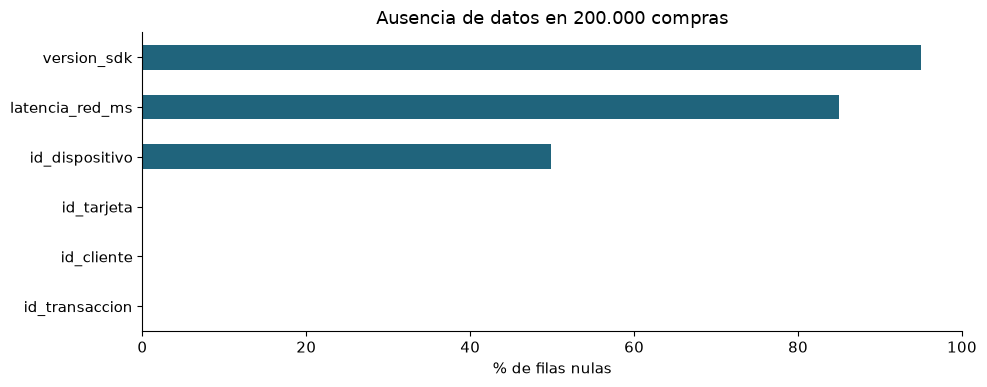

In [4]:
perfil = pd.DataFrame({'tipo':transacciones.dtypes.astype(str),
    'nulos_pct':transacciones.isna().mean()*100,
    'distintos':transacciones.nunique(dropna=True),
    'moda_pct':transacciones.apply(lambda s: s.value_counts(normalize=True).iloc[0]*100 if s.notna().any() else np.nan)})
display(perfil.sort_values('nulos_pct',ascending=False).round(2))
perfil.nlargest(6,'nulos_pct').nulos_pct.sort_values().plot.barh(color='#20647c')
plt.xlabel('% de filas nulas'); plt.title('Ausencia de datos en 200.000 compras'); plt.xlim(0,100); plt.tight_layout(); plt.show()

## 4. Aplicar reglas explícitas de limpieza
Normalizamos moneda local y canal. Montos no recuperables, no positivos o superiores al cupo pasan a nulo; no eliminamos sus filas. La mediana se aprenderá exclusivamente con entrenamiento en el siguiente notebook. Reconstruimos fecha y hora desde el timestamp canónico. Consulte `python/taller.py::clean_transactions` para revisar el código.

**Decisión:** no corregir `1O0O` suponiendo que significa mil. Tampoco asumir que toda compra grande es fraude.

In [5]:
limpias, calidad = clean_transactions(transacciones, clientes)
display(pd.Series(calidad, name='resultado').to_frame())
assert len(limpias)==len(transacciones)
assert limpias.monto_cop.isna().sum()==4000
assert limpias.canal.isin(['POS','WEB','APP']).all()
assert (limpias.fecha==limpias.fecha_hora.dt.strftime('%Y-%m-%d')).all()
display(limpias[['monto_cop','canal','fecha','hora']].head())

,resultado
filas_entrada,200000
filas_salida,200000
montos_formato_local_recuperados,2000
montos_invalidos_a_nulo,4000
canales_normalizados,2000
fechas_reconstruidas,3000
horas_reconstruidas,1000


,monto_cop,canal,fecha,hora
0,54014.54,POS,2026-01-01,00:05:46
1,221940.89,APP,2026-01-01,00:06:08
2,244916.41,APP,2026-01-01,00:06:56
3,128106.97,WEB,2026-01-01,00:09:47
4,74197.53,POS,2026-01-01,00:09:48


## 5. Construir historia sin mirar el futuro
Para cada cliente ordenamos por timestamp y calculamos compras de la hora anterior, suma de montos de las últimas 24 horas, promedio previo, novedad de comercio/dispositivo y tiempo desde la compra anterior. La compra actual se añade al historial después del cálculo. Los primeros registros no tienen media previa.

El historial de compras puede usarse aunque todavía no se conozca su etiqueta. El historial de fraude requeriría controlar cuándo se confirmó cada caso.

In [6]:
base, calidad = prepare_dataset()
assert len(base)==200_000 and base.es_fraude.sum()==50_000
primera = base.sort_values(['fecha_hora','id_transaccion']).groupby('id_cliente').head(1)
assert primera.media_monto_previo.isna().all()
assert primera.compras_previas_1h.eq(0).all()
display(base[['id_cliente','fecha_hora','monto_cop','media_monto_previo','compras_previas_1h','dispositivo_nuevo']].head(8))

,id_cliente,fecha_hora,monto_cop,media_monto_previo,compras_previas_1h,dispositivo_nuevo
0,CLI03199,2026-01-01 00:05:46,54014.54,NaN,0,NaN
1,CLI04573,2026-01-01 00:06:08,221940.89,NaN,0,1.0
2,CLI00371,2026-01-01 00:06:56,244916.41,NaN,0,1.0
3,CLI03640,2026-01-01 00:09:47,128106.97,NaN,0,1.0
4,CLI02623,2026-01-01 00:09:48,74197.53,NaN,0,NaN
5,CLI00735,2026-01-01 00:13:24,49339.54,NaN,0,NaN
6,CLI04744,2026-01-01 00:13:49,97582.98,NaN,0,1.0
7,CLI03207,2026-01-01 00:14:08,66752.93,NaN,0,1.0


## 6. Explorar comportamientos
Este EDA global describe el conjunto sintético completo; no se utiliza para ajustar hiperparámetros ni seleccionar el umbral. En una evaluación ciega estricta, reserve también el EDA de prueba. Las asociaciones observadas no demuestran causalidad ni autoría del fraude.

,compras,fraudes,tasa
canal,,,
APP,40081,12552,0.313166
POS,99684,18652,0.187111
WEB,60235,18796,0.312044


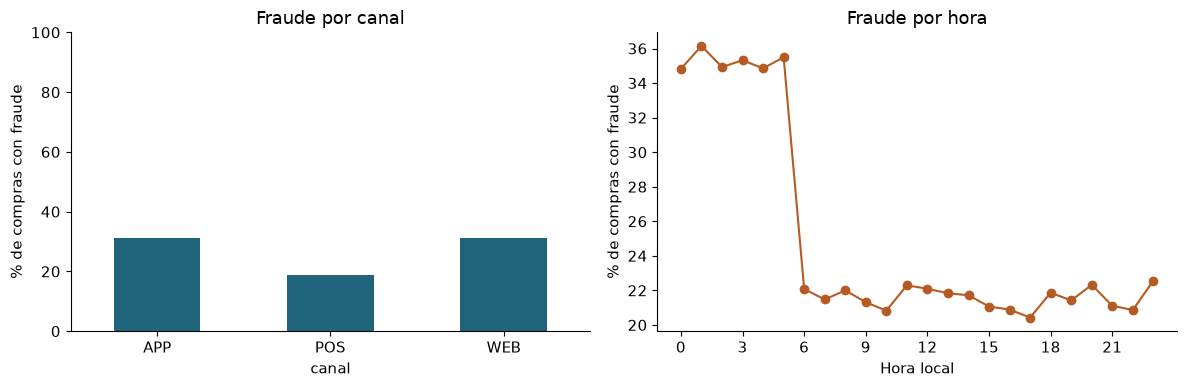

In [7]:
por_canal = base.groupby('canal').agg(compras=('es_fraude','size'),fraudes=('es_fraude','sum'),tasa=('es_fraude','mean'))
display(por_canal)
fig, axes = plt.subplots(1,2,figsize=(12,4))
por_canal.tasa.mul(100).plot.bar(ax=axes[0],color='#20647c',rot=0)
axes[0].set(ylabel='% de compras con fraude',title='Fraude por canal',ylim=(0,100))
base.groupby(base.fecha_hora.dt.hour).es_fraude.mean().mul(100).plot(ax=axes[1],marker='o',color='#b55b23')
axes[1].set(xlabel='Hora local',ylabel='% de compras con fraude',title='Fraude por hora',xticks=range(0,24,3))
plt.tight_layout(); plt.show()

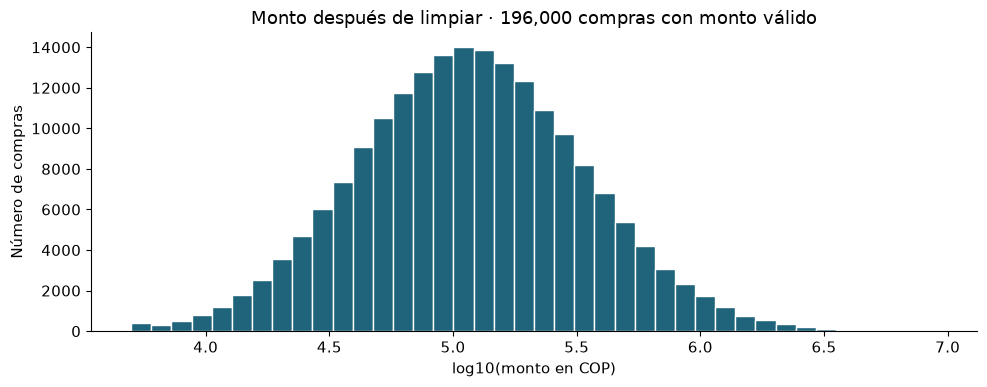

Los nulos no aparecen en este histograma: 4000


In [8]:
validos = base.monto_cop.dropna()
plt.hist(np.log10(validos),bins=40,color='#20647c',edgecolor='white')
plt.title(f'Monto después de limpiar · {len(validos):,} compras con monto válido')
plt.xlabel('log10(monto en COP)'); plt.ylabel('Número de compras'); plt.tight_layout(); plt.show()
print('Los nulos no aparecen en este histograma:', int(base.monto_cop.isna().sum()))

## Comprobaciones y entrega
Se guardaron `artifacts/base_modelo.parquet` y `artifacts/calidad.json`. Se conservaron todas las compras, y cada variable histórica utiliza únicamente datos previos.

**Evidencia individual:** capture el perfil de calidad, una comprobación de llaves y un gráfico. Escriba por qué un monto inválido se convirtió a nulo y por qué no se imputó antes de separar entrenamiento.

**Prompt para Codex:** «Revisa `clean_transactions` y `historical_features`. Identifica si una compra actual o futura puede alterar el historial previo. Propón una prueba que detecte ese error y ejecútala sin utilizar las etiquetas».

Continúe con `02_modelos_validacion.ipynb`.